In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
os.environ["KERAS_BACKEND"] = "torch"
import torch
import keras

## Constants - Base setup values

In [2]:
max_dim = 6
max_color = 3


In [3]:
def new_box(size):
  box = np.random.randint(max_dim - size, size=(1,4))
  box[0,2] = box[0,0] + size
  box[0,3] = box[0,1] + size
  return box

def no_overlap(boxes, box2, space):
# assume box1 is same size or bigger than box2.  No overlap if no point of box2
# is inside box1.  Uses space to grow size of box1.
# Generalize to box1 being an array of boxes.
  for box1 in boxes:
    if   box1[0]-space < box2[0] and box1[2]+space > box2[0] and box1[1]-space < box2[1] and box1[3]+space > box2[1]:
      return False
    elif box1[0]-space < box2[0] and box1[2]+space > box2[0] and box1[1]-space < box2[3] and box1[3]+space > box2[3]:
      return False
    elif box1[0]-space < box2[2] and box1[2]+space > box2[2] and box1[1]-space < box2[1] and box1[3]+space > box2[1]:
      return False
    elif box1[0]-space < box2[2] and box1[2]+space > box2[2] and box1[1]-space < box2[3] and box1[3]+space > box2[3]:
      return False
  return True



In [4]:
# build box_array starting with the largest box

def generate_boxes(number_boxes=4, box_size=8, space=1):
  box_array = new_box(box_size)
  size = box_size//2
  for i in range(number_boxes-1):
    next_box = new_box(size)
    count = 0
    while not no_overlap(box_array, next_box[0], space):
      if count < 5:
        count += 1
      else:
        size = size//2
        if size < 1:
          size = 1
        count = 0
      next_box = new_box(size)
    box_array = np.append(box_array, next_box, axis=0)
  return box_array

In [5]:
# Generate random colors for background and boxes
def generate_images(random_background, number_boxes, box_size, space):
  if random_background:
    background = np.random.randint(max_color)
    color_array = np.random.randint(max_color, size=(1,number_boxes))
    for box in range(number_boxes):
      if color_array[0,box] == background:
        if color_array[0,box] == 0:
          color_array[0,box] = 1
        else:
          color_array[0,box] = background - 1
  else:
    background = 0
    color_array = np.random.randint(1, high=max_color+1, size=(1,number_boxes))

  box_array = np.concatenate((generate_boxes(number_boxes, box_size, space), color_array.T), axis=1)

  a = np.ones((max_dim, max_dim))
  a = a * background
  for box in box_array:
    a[box[0]:box[2], box[1]:box[3]] = box[4]
  b = np.zeros((max_dim,max_dim))
  b[box_array[0,0]:box_array[0,2], box_array[0,1]:box_array[0,3]] = 1
  return (a,b)


/tmp/ipykernel_520592/3704442732.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  figure.show()


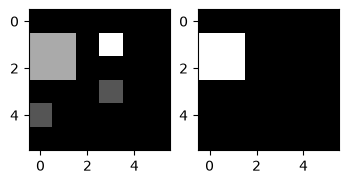

In [6]:
a, b = generate_images(False, 4, 2, 1)
figure = plt.figure(figsize=(4,2))
col, row = 2, 1
figure.add_subplot(row, col, 1)
plt.imshow(a,cmap='gray')
figure.add_subplot(row, col, 2)
plt.imshow(b,cmap='gray')
figure.show()

In [7]:
print(a)

[[0. 0. 0. 0. 0. 0.]
 [2. 2. 0. 3. 0. 0.]
 [2. 2. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


In [8]:
def expand(array):
    b = np.zeros((max_dim, max_dim, max_color+1), np.float16) 
    for x in range(max_dim):
        for y in range(max_dim):
            b[x][y][int(array[x][y])] = 1.0
    return b

c = expand(a)
print(c.shape)

(6, 6, 4)


In [9]:
train_in, train_out = list(), list()

for _ in range(100):
    a, b = generate_images(False, 4, 2, 1)
    train_in.append(expand(a))
    train_out.append(b)

train_in = np.array(train_in)
train_out = np.array(train_out)
print(train_in.shape)
print(train_out.shape)

(100, 6, 6, 4)
(100, 6, 6)


In [20]:
input = keras.layers.Input(shape=(max_dim, max_dim, max_color+1))
x = keras.layers.Conv2D(16, (2, 2), activation="relu", padding="valid")(input)
x = keras.layers.Conv2D(32, (3, 3), activation="relu", padding="valid")(x)

x = keras.layers.Conv2DTranspose(32, (3, 3), strides=1, activation="relu", padding="valid")(x)
x = keras.layers.Conv2DTranspose(32, (2, 2), strides=1, activation="relu", padding="valid")(x)
x = keras.layers.Conv2D(1, (1, 1), activation="sigmoid", padding="valid")(x)

autoencoder = keras.models.Model(input, x)
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 6, 6, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 5, 5, 16)       │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 3, 3, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 5, 5, 32)       │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 6, 6, 32)       │         4,128 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 6, 6, 1)        │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,321 (71.57 KB)

 Trainable params: 18,321 (71.57 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
test_in, test_out = list(), list()

for _ in range(10):
    a, b = generate_images(False, 4, 2, 1)
    test_in.append(expand(a))
    test_out.append(b)

test_in = np.array(test_in)
test_out = np.array(test_out)
print(test_in.shape)
print(test_out.shape)

(10, 6, 6, 4)
(10, 6, 6)


In [27]:
autoencoder.fit(
    x=train_in,
    y=train_out,
    epochs=10,
    batch_size=20,
    shuffle=True,
    validation_data=(test_in, test_out),
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 2.8043e-04 - val_loss: 0.0017
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.6714e-04 - val_loss: 0.0017
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 2.5429e-04 - val_loss: 0.0017
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 2.4191e-04 - val_loss: 0.0016
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 2.3112e-04 - val_loss: 0.0016
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 2.2189e-04 - val_loss: 0.0015
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 2.1107e-04 - val_loss: 0.0015
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 2.0224e-04 - val_loss: 0.0015
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 1.9388e-04 - val_loss: 0.0014
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 1.8644e-04 - val_loss: 0.0014


In [28]:
def display(array1, array2):
    """Displays ten random images from each array."""
    n = 5
    indices = np.random.randint(len(array1), size=n)
    images1 = array1[indices, :]
    images2 = array2[indices, :]

    plt.figure(figsize=(20, 4))
    for i, (image1, image2) in enumerate(zip(images1, images2)):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(image1)
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(image2)
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


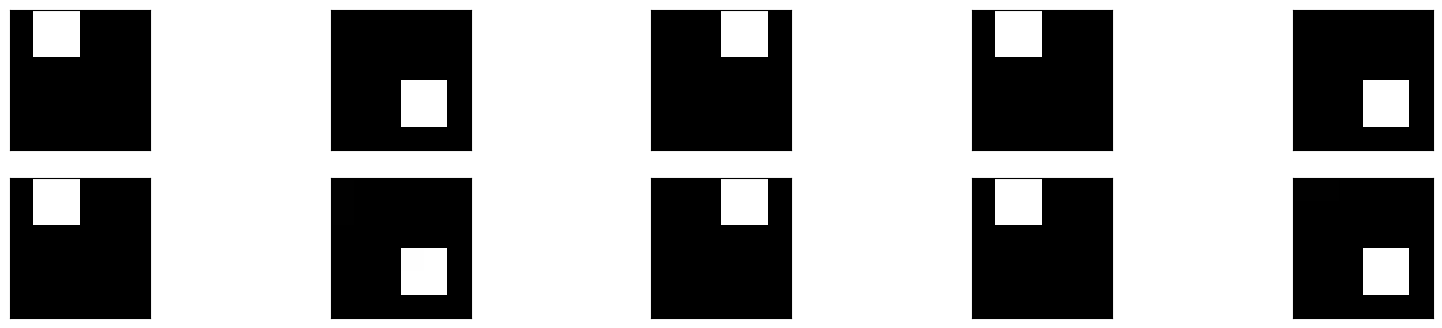

In [29]:
predictions = autoencoder.predict(test_in)
display(test_out, predictions)